# 02 · Healthy lung atlas: doublet removal, QC and normalisation

Second step of the healthy-lung pipeline (paper Methods: *Non-malignant lung single cell data processing*).

**Input**: `intermediate_files/lung/01_lung_sikkema_atlas_raw_normal.h5ad` (File 01: full HLCA, all donors with ≥ 100 cells, raw counts and Scrublet doublet scores)

**Steps**
1. Use gene symbols as variable names.
2. Remove predicted doublets.
3. Annotate mitochondrial, ribosomal and haemoglobin genes and compute QC metrics (`sc.pp.calculate_qc_metrics`). The metrics are inspected but not used for filtering.
4. Keep healthy and tumour-adjacent healthy lung samples.
5. Filter cells with < 200 genes and genes expressed in < 3 cells; normalise to median total counts and log-transform.
6. Select the top 2,000 highly variable genes using `sample` as the batch key.

**Output**: `intermediate_files/lung/adata_preprocessed.h5ad`. AT2 selection, PCA and Harmony integration follow in File 03.

*Note*: the outputs of sections 3–5 were not saved in this copy of the notebook, so those cells show no execution count or plots.

## Setup

In [1]:
import gc
import random
import re

import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import seaborn as sns

# Random seeds
np.random.seed(1)
random.seed(1)

# Scanpy settings
sc.settings.verbosity = 0  # errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=250)

# Seaborn / Matplotlib settings
sns.set_context("paper", font_scale=0.9)
plt.rcParams['svg.fonttype'] = 'none'  # keep fonts editable in saved SVGs

In [2]:
# Paths: edit to match your environment
DATA_DIR = "intermediate_files/lung"
IN_H5AD = f"{DATA_DIR}/01_lung_sikkema_atlas_raw_normal.h5ad"   # output of File 01
OUT_H5AD = f"{DATA_DIR}/adata_preprocessed.h5ad"
FIG_DIR = "."

## 1. Load data and use gene symbols as variable names

In [3]:
adata = sc.read(IN_H5AD)

In [4]:
adata.var['ensid'] = adata.var_names  # keep the original var names (gene symbols, some with an _ENSG suffix)

In [5]:
adata.var

,feature_name,feature_reference,feature_biotype,feature_length,feature_type,ensid
A1BG_ENSG00000121410,A1BG_ENSG00000121410,NCBITaxon:9606,gene,2134,protein_coding,ENSG00000121410
A1BG-AS1,A1BG-AS1,NCBITaxon:9606,gene,1667,lncRNA,ENSG00000268895
A1CF_ENSG00000148584,A1CF_ENSG00000148584,NCBITaxon:9606,gene,2211,protein_coding,ENSG00000148584
A2M_ENSG00000175899,A2M_ENSG00000175899,NCBITaxon:9606,gene,590,protein_coding,ENSG00000175899
A2M-AS1,A2M-AS1,NCBITaxon:9606,gene,2551,lncRNA,ENSG00000245105
...,...,...,...,...,...,...
RAB1B_ENSG00000174903,RAB1B_ENSG00000174903,NCBITaxon:9606,gene,1446,protein_coding,ENSG00000174903
STC1_ENSG00000159167,STC1_ENSG00000159167,NCBITaxon:9606,gene,2808,protein_coding,ENSG00000159167
STXBP1_ENSG00000136854,STXBP1_ENSG00000136854,NCBITaxon:9606,gene,2918,protein_coding,ENSG00000136854
TEC_ENSG00000135605,TEC_ENSG00000135605,NCBITaxon:9606,gene,814,protein_coding,ENSG00000135605


In [6]:
adata.var['feature_base'] = adata.var['feature_name'].str.replace(r'_ENSG.*', '', regex=True)
adata.var_names = adata.var['feature_base']  # use gene symbols as var names
adata.var_names.name = None
adata.var_names_make_unique()

## 2. Remove predicted doublets

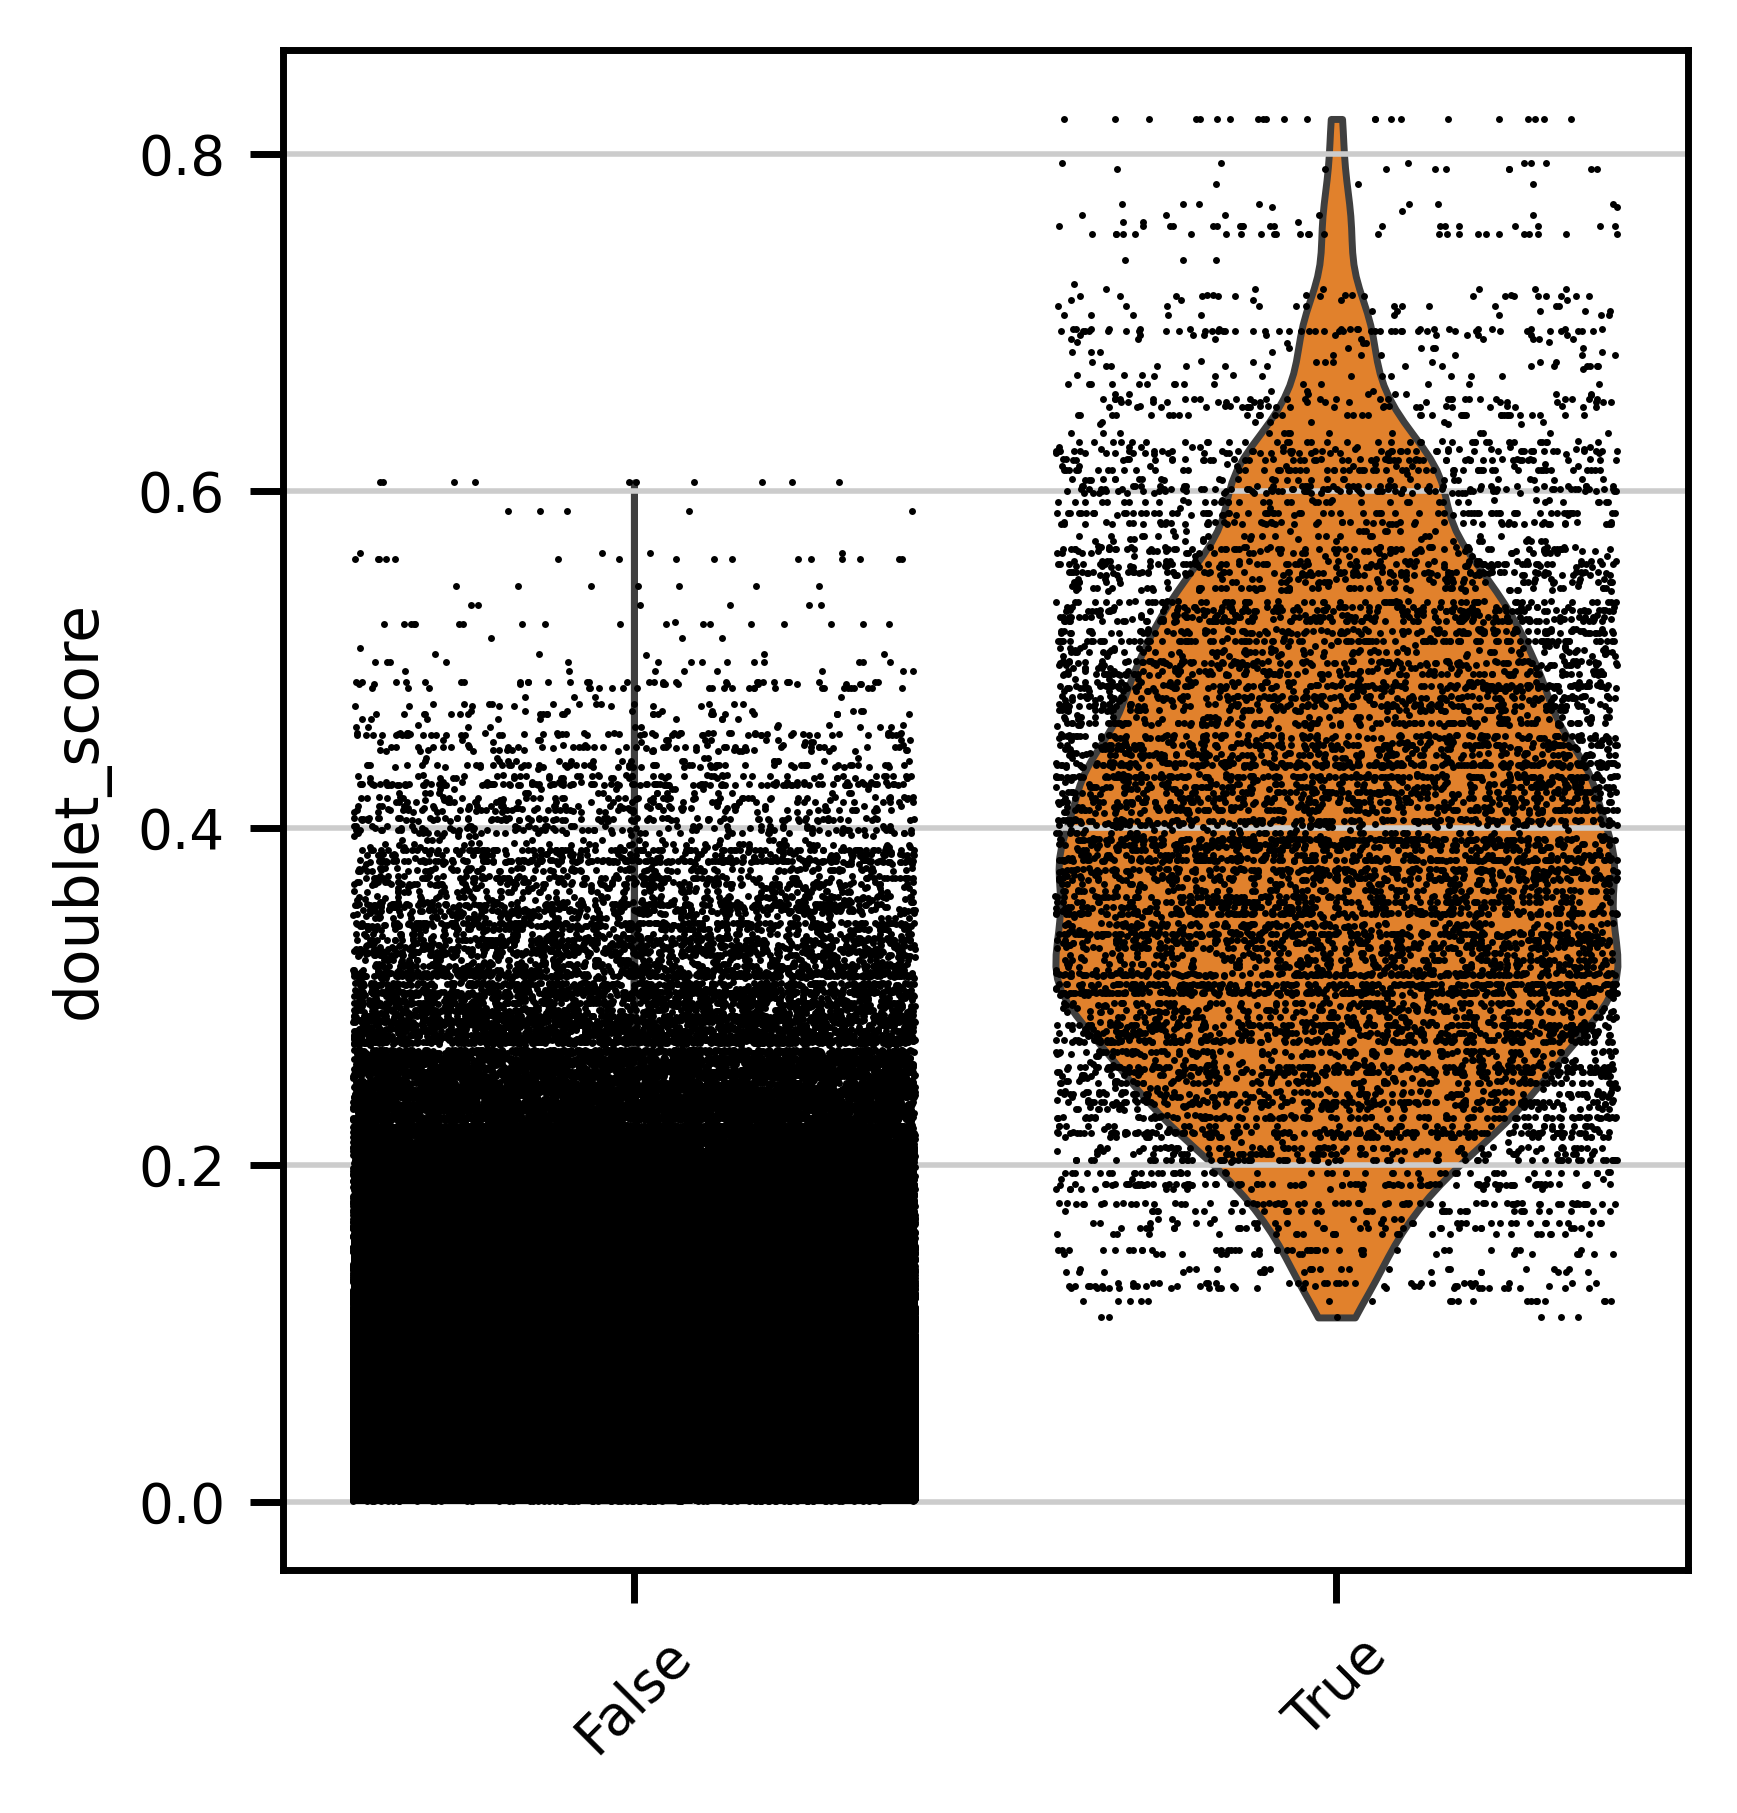

5069

In [7]:
adata.obs['doublet_info'] = adata.obs["predicted_doublet"].astype(str)

sc.pl.violin(adata, 'doublet_score', jitter=0.4, groupby='doublet_info', rotation=45)
plt.savefig(f"{FIG_DIR}/violin_plot_doublets.svg", format="svg")
gc.collect()

In [8]:
adata = adata[adata.obs['predicted_doublet'].isin([False])]
print(f"Filtered data shape: {adata.shape}")

Filtered data shape: (2271922, 56239)


In [9]:
# Check that no gene symbols still carry an Ensembl ID suffix
pattern = re.compile(r'.+_ENSG\d+')

def count_matching_genes(var_names, pattern):
    return sum(1 for name in var_names if pattern.match(name))

matching_genes_count = count_matching_genes(adata.var_names, pattern)
print(f"Number of genes matching the pattern: {matching_genes_count}")

## 3. Quality-control metrics

In [ ]:
# Annotate mitochondrial, ribosomal and haemoglobin genes
adata.var["mt"] = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")

sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True)

/tmp/ipykernel_3392563/3842873950.py:2: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var["mt"] = adata.var_names.str.startswith("MT-")


In [ ]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)
plt.savefig(f"{FIG_DIR}/violin_plot_prepros.svg", format="svg")

In [ ]:
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

## 4. Keep healthy lung samples

In [ ]:
adata = adata[adata.obs['lung_condition'].isin(['Healthy', 'Healthy (tumor adjacent)'])]

## 5. Filter, normalise, select highly variable genes and save

In [ ]:
# Filter cells and genes
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

# Keep raw counts
adata.layers["counts"] = adata.X.copy()

# Normalise each cell to the median total count, then log-transform
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

# Top 2,000 highly variable genes, batch-aware by sample
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="sample")
sc.pl.highly_variable_genes(adata)

adata.write(OUT_H5AD)